# DATERAQUEST 2.0 — Data Probe (plant image classification)

Internal exploration notebook for the team. It answers one question before any model is trained:
**what in this dataset can hurt our Macro F1 or get us disqualified?**

What it checks, in order:

| # | Check | Why it matters |
|---|-------|----------------|
| 1 | Folder layout and CSV consistency (`train.csv`, `class_mapping.csv`, `sample_submission.csv`) | Wrong id ↔ file mapping silently ruins training or the submission |
| 2 | Class balance | Macro F1 weights every class equally; small classes decide the score |
| 3 | File integrity (corrupt, wrong extension, colour mode, EXIF rotation) | Crashes or silently rotated images during training |
| 4 | Geometry, colour, sharpness per class and train vs test | Shortcuts (e.g. a class is always portrait) and train/test shift |
| 5 | Exact and near-duplicate images | Duplicates inflate CV; cross-class duplicates are label noise |
| 6 | Adversarial validation (train vs test, unlabeled) | Tells whether CV scores will transfer to the leaderboard |
| 7 | From-scratch signal floor (hand-crafted features, no pretrained weights) | A baseline Macro F1 your CNN must beat |

**Rules guardrails built into this probe** (Ketentuan MLC DATERAQUEST 2.0):
- Test images are used **only as aggregate statistics** (sizes, colours, a train-vs-test classifier). The probe never shows individual test images and never assigns labels to test files, because hand-labeling or manual analysis of test data is a disqualification reason (Sanksi 6).
- No pretrained weights, no VLMs, no AutoML. The baseline uses scikit-learn on hand-crafted features computed from the competition data only.
- All random seeds are fixed.

**How to run:** on Kaggle, attach the competition data and *Run All*. Locally, set `DQ_DATA_DIR` to the folder that holds `train/`, `test/` and the CSVs (or put this notebook next to a `Dataset/` folder). Outputs go to `probe_out/`.

In [1]:
import os, io, re, json, time, hashlib, random, warnings
from pathlib import Path
from collections import Counter, defaultdict
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)

DATA_DIR    = os.environ.get("DQ_DATA_DIR", "")               # leave empty for auto-discovery
OUT_DIR     = Path(os.environ.get("DQ_OUT_DIR", "probe_out"))
MAX_IMAGES  = int(os.environ.get("DQ_MAX_IMAGES", "0"))       # 0 = scan every image; >0 = random subset per split
N_WORKERS   = min(16, (os.cpu_count() or 2) * 2)
NEAR_T      = 6                                               # dHash Hamming distance (of 64 bits) counted as near-duplicate
IMG_EXT     = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff", ".gif"}

OUT_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_rows", 80)
pd.set_option("display.width", 160)

FINDINGS = []   # (level, message); level in BLOCKER / WARN / INFO
def flag(level, msg):
    FINDINGS.append((level, msg))
    print(f"[{level}] {msg}")

def savefig(name):
    plt.tight_layout()
    plt.savefig(OUT_DIR / f"{name}.png", dpi=110, bbox_inches="tight")
    plt.show()

print("workers:", N_WORKERS, "| output:", OUT_DIR.resolve())

workers: 16 | output: C:\Users\Cassini\Documents\DTR_Moyim\probe_out


## 1. Locate the data

Searches `DQ_DATA_DIR`, `./Dataset`, the current folder and `/kaggle/input` (up to three levels deep) for `train.csv`. Single nested wrappers such as `train/train/` are unwrapped automatically.

In [2]:
def _glob_depth(base, name, max_depth=3):
    for d in range(max_depth + 1):
        pat = "/".join(["*"] * d + [name]) if d else name
        hits = sorted(base.glob(pat))
        if hits:
            return hits[0]
    return None

def find_root():
    bases = [Path(DATA_DIR)] if DATA_DIR else []
    bases += [Path.cwd() / "Dataset", Path.cwd(), Path.cwd().parent / "Dataset", Path("/kaggle/input")]
    for base in bases:
        if not base.exists():
            continue
        for marker in ("train.csv", "sample_submission.csv", "class_mapping.csv"):
            hit = _glob_depth(base, marker)
            if hit is not None:
                return hit.parent
    raise FileNotFoundError("Could not find train.csv / class_mapping.csv. Set DQ_DATA_DIR.")

def unwrap(d):
    # Follow single-child folders (train/train/...) until we reach the real content.
    while d is not None and d.is_dir():
        kids = [p for p in d.iterdir() if not p.name.startswith(".")]
        subs = [p for p in kids if p.is_dir()]
        imgs = [p for p in kids if p.is_file() and p.suffix.lower() in IMG_EXT]
        if len(subs) == 1 and not imgs:
            d = subs[0]
        else:
            break
    return d

def find_dir(root, names):
    for n in names:
        for cand in [root / n] + sorted(root.glob(f"*/{n}")):
            if cand.is_dir():
                return unwrap(cand)
    return None

ROOT      = find_root()
TRAIN_DIR = find_dir(ROOT, ["train", "Train", "train_images"])
TEST_DIR  = find_dir(ROOT, ["test", "Test", "test_images"])

def find_csv(name):
    p = _glob_depth(ROOT, name, 2)
    return p

P_TRAIN_CSV = find_csv("train.csv")
P_MAP_CSV   = find_csv("class_mapping.csv")
P_SUB_CSV   = find_csv("sample_submission.csv")

for k, v in dict(ROOT=ROOT, TRAIN_DIR=TRAIN_DIR, TEST_DIR=TEST_DIR, train_csv=P_TRAIN_CSV,
                 class_mapping=P_MAP_CSV, sample_submission=P_SUB_CSV).items():
    print(f"{k:18s} {v}")

for name, p in [("train/", TRAIN_DIR), ("test/", TEST_DIR), ("train.csv", P_TRAIN_CSV),
                ("class_mapping.csv", P_MAP_CSV), ("sample_submission.csv", P_SUB_CSV)]:
    if p is None:
        flag("BLOCKER" if name in ("train/", "train.csv") else "WARN", f"{name} not found; related checks are skipped.")

ROOT               c:\Users\Cassini\Documents\DTR_Moyim\Dataset
TRAIN_DIR          None
TEST_DIR           None
train_csv          None
class_mapping      c:\Users\Cassini\Documents\DTR_Moyim\Dataset\class_mapping.csv
sample_submission  None
[BLOCKER] train/ not found; related checks are skipped.
[WARN] test/ not found; related checks are skipped.
[BLOCKER] train.csv not found; related checks are skipped.
[WARN] sample_submission.csv not found; related checks are skipped.


## 2. File inventory

In [3]:
def inventory(d):
    imgs, other = [], []
    if d is None:
        return imgs, other
    for p in sorted(d.rglob("*")):
        if p.is_file():
            (imgs if p.suffix.lower() in IMG_EXT else other).append(p)
    return imgs, other

train_paths, train_other = inventory(TRAIN_DIR)
test_paths,  test_other  = inventory(TEST_DIR)

def folder_label(folder):
    m = re.match(r"^(\d+)_", folder)
    return int(m.group(1)) if m else np.nan

files = pd.DataFrame({
    "path": [str(p) for p in train_paths],
    "rel":  [p.relative_to(TRAIN_DIR).as_posix() for p in train_paths],
})
files["folder"] = files["rel"].map(lambda r: r.split("/")[0] if "/" in r else "")
files["name"]   = files["rel"].map(lambda r: r.split("/")[-1])
files["label_folder"] = files["folder"].map(folder_label)
files["ext"]    = files["name"].map(lambda n: Path(n).suffix.lower())

test_files = pd.DataFrame({"path": [str(p) for p in test_paths],
                           "name": [p.relative_to(TEST_DIR).as_posix() for p in test_paths]})

print(f"train images: {len(files):,} in {files['folder'].nunique()} folders")
print(f"test images : {len(test_files):,}")
print("train extensions:", dict(Counter(files['ext'])))
print("test extensions :", dict(Counter(test_files['name'].map(lambda n: Path(n).suffix.lower()))))

if train_other or test_other:
    flag("WARN", f"{len(train_other) + len(test_other)} non-image files inside train/test "
                 f"(e.g. {[p.name for p in (train_other + test_other)[:5]]}). Make the loader filter by extension.")
if (files["folder"] == "").any():
    flag("WARN", f"{(files['folder'] == '').sum()} train images sit directly in train/ without a class folder.")
if files["label_folder"].isna().any():
    bad = sorted(files.loc[files['label_folder'].isna(), 'folder'].unique())[:10]
    flag("WARN", f"Class folders without a '<label>_' prefix: {bad}")
nested = files["rel"].map(lambda r: r.count("/")).max() if len(files) else 0
if nested and nested > 1:
    flag("INFO", "Some train images sit deeper than one folder level; the loader must use rglob.")

train images: 0 in 0 folders
test images : 0
train extensions: {}
test extensions : {}


## 3. CSV consistency

### 3a. `class_mapping.csv`

In [4]:
cm = pd.read_csv(P_MAP_CSV) if P_MAP_CSV else pd.DataFrame(columns=["label", "species", "folder_name"])
display(cm.head(40)) if len(cm) else print("no class_mapping.csv")

if len(cm):
    if cm["label"].duplicated().any():
        flag("BLOCKER", "class_mapping has duplicated labels.")
    labels = sorted(cm["label"].astype(int))
    if labels != list(range(len(labels))):
        flag("WARN", f"class_mapping labels are not contiguous 0..{len(labels) - 1}: {labels}")
    if "folder_name" in cm:
        actual  = set(files["folder"]) - {""}
        mapped  = set(cm["folder_name"])
        if mapped - actual:
            flag("BLOCKER", f"Folders listed in class_mapping but missing in train/: {sorted(mapped - actual)}")
        if actual - mapped:
            flag("BLOCKER", f"Folders in train/ not listed in class_mapping: {sorted(actual - mapped)}")
        pref = cm["folder_name"].map(folder_label)
        if (pref != cm["label"]).any():
            flag("WARN", "folder_name prefix disagrees with label in class_mapping: "
                         f"{cm.loc[pref != cm['label'], ['label', 'folder_name']].values.tolist()}")

NUM_CLASSES = len(cm) if len(cm) else int(files["label_folder"].nunique())
SPECIES = dict(zip(cm["label"].astype(int), cm["species"])) if len(cm) else {i: str(i) for i in range(NUM_CLASSES)}
print("NUM_CLASSES =", NUM_CLASSES)

# Classes that share a genus are the most likely fine-grained confusions.
genus = pd.Series({k: re.split(r"[_ ]", v)[0].capitalize() for k, v in SPECIES.items()})
shared = genus[genus.duplicated(keep=False)].groupby(genus).apply(lambda s: [f"{i}:{SPECIES[i]}" for i in s.index])
if len(shared):
    print("\nClasses sharing a genus (expect confusion between these):")
    for g, members in shared.items():
        print(f"  {g}: {members}")

,label,species,folder_name
0,0,Albizia_saponaria,0_Albizia_saponaria
1,1,Alocasia_Black_Velvet,1_Alocasia_Black_Velvet
2,2,Anacampseros_rufescens_Sunrise,2_Anacampseros_rufescens_Sunrise
3,3,Apocynacaea,3_Apocynacaea
4,4,Areca_catechu_L,4_Areca_catechu_L
5,5,Catharanthus_roseus,5_Catharanthus_roseus
6,6,Ceiba_pentandra,6_Ceiba_pentandra
7,7,Cuphea_hyssopifolia_kunth,7_Cuphea_hyssopifolia_kunth
8,8,Cymbidium_bicolor,8_Cymbidium_bicolor
9,9,Dendrobium_Uthai_White,9_Dendrobium_Uthai_White


[BLOCKER] Folders listed in class_mapping but missing in train/: ['0_Albizia_saponaria', '10_Dendrobium_leonis', '11_Dracaena_Trifasciata_Mabb', '12_Echinodorus_radican', '13_Gymnocalycium', '14_Hopea_Bilitonensis_P_S_Ashton', '15_Impatiens_walleriana', '16_Lagerstroemia_speciosa', '17_Lxora_acuminata', '18_Monstera_Adansonii', '19_Nepenthes_Sumatrana', '1_Alocasia_Black_Velvet', '20_Nepenthes_reinwardtiana_Miq', '21_Ochna_kirkii', '22_Philodendron_Lemon', '23_Portulaca_Sp', '24_Quassia_amara', '25_Reutealis_trisperma', '26_Rosa_sp', '27_Russelia_equisetiformis', '28_Syzygium_myrtifolium_walp', '29_Tabernaemontana_corymbosa_Roxb_ex_Wall', '2_Anacampseros_rufescens_Sunrise', '3_Apocynacaea', '4_Areca_catechu_L', '5_Catharanthus_roseus', '6_Ceiba_pentandra', '7_Cuphea_hyssopifolia_kunth', '8_Cymbidium_bicolor', '9_Dendrobium_Uthai_White']
NUM_CLASSES = 30

Classes sharing a genus (expect confusion between these):
  Dendrobium: ['9:Dendrobium_Uthai_White', '10:Dendrobium_leonis']
  Nepent

### 3b. `train.csv` ↔ files on disk

The `id` column may be a bare file name (`0_1.jpg`), a relative path (`0_Albizia_saponaria/0_1.jpg`) or a name without extension. Each id is resolved in that order and must point to exactly one file.

In [5]:
def build_index(rels):
    by_rel, by_name, by_stem = {}, defaultdict(list), defaultdict(list)
    for i, r in enumerate(rels):
        by_rel[r] = i
        n = r.split("/")[-1]
        by_name[n].append(i)
        by_stem[n.rsplit(".", 1)[0]].append(i)
    return by_rel, by_name, by_stem

def resolve(idv, index):
    by_rel, by_name, by_stem = index
    s = str(idv).strip().replace("\\", "/").lstrip("./")
    if s in by_rel:
        return by_rel[s], "relpath"
    for prefix in ("train/", "test/"):
        if s.startswith(prefix) and s[len(prefix):] in by_rel:
            return by_rel[s[len(prefix):]], "relpath"
    b = s.split("/")[-1]
    if len(by_name.get(b, [])) == 1:
        return by_name[b][0], "filename"
    if len(by_name.get(b, [])) > 1:
        return None, "ambiguous"
    st = b.rsplit(".", 1)[0] if "." in b else b
    if len(by_stem.get(st, [])) == 1:
        return by_stem[st][0], "stem"
    return None, "missing"

tr = pd.read_csv(P_TRAIN_CSV) if P_TRAIN_CSV else pd.DataFrame(columns=["id", "label"])
print("train.csv shape:", tr.shape, "| columns:", list(tr.columns))
display(tr.head())

if set(["id", "label"]) - set(tr.columns):
    flag("BLOCKER", f"train.csv columns are {list(tr.columns)}, expected id,label.")
else:
    n_null = tr[["id", "label"]].isna().sum()
    if n_null.any():
        flag("WARN", f"train.csv nulls: {n_null.to_dict()}")
    if tr["id"].duplicated().any():
        flag("WARN", f"{tr['id'].duplicated().sum()} duplicated ids in train.csv")
    lab = pd.to_numeric(tr["label"], errors="coerce")
    if lab.isna().any() or (lab % 1 != 0).any():
        flag("BLOCKER", "train.csv label column has non-integer values.")
    out = (~lab.between(0, NUM_CLASSES - 1)).sum()
    if out:
        flag("BLOCKER", f"{out} labels outside 0..{NUM_CLASSES - 1}")

    idx = build_index(files["rel"].tolist())
    res = tr["id"].map(lambda v: resolve(v, idx))
    tr["file_i"] = res.map(lambda t: t[0])
    tr["how"]    = res.map(lambda t: t[1])
    print("id resolution:", dict(Counter(tr["how"])))
    miss = tr[tr["file_i"].isna()]
    if len(miss):
        flag("BLOCKER", f"{len(miss)} train.csv ids do not match any image (e.g. {miss['id'].head(5).tolist()})")
    matched = set(tr["file_i"].dropna().astype(int))
    orphan = files.index.difference(list(matched))
    if len(orphan):
        flag("WARN", f"{len(orphan)} images on disk are not listed in train.csv "
                     f"(e.g. {files.loc[orphan, 'rel'].head(5).tolist()}). Decide: use folder label or drop.")
    ok = tr.dropna(subset=["file_i"]).copy()
    ok["file_i"] = ok["file_i"].astype(int)
    ok["label_folder"] = files.loc[ok["file_i"], "label_folder"].values
    mism = ok[pd.to_numeric(ok["label"], errors="coerce") != ok["label_folder"]]
    if len(mism):
        flag("WARN", f"{len(mism)} rows where train.csv label != folder label "
                     f"(e.g. {mism[['id', 'label', 'label_folder']].head(5).values.tolist()}). One of them is wrong.")
    else:
        print("train.csv labels agree with folder labels for every matched row.")

# Final training table: csv label where available, else folder label.
files["label_csv"] = np.nan
if "file_i" in tr:
    tmp = tr.dropna(subset=["file_i"])
    files.loc[tmp["file_i"].astype(int).values, "label_csv"] = pd.to_numeric(tmp["label"], errors="coerce").values
files["label"] = files["label_csv"].fillna(files["label_folder"])
files = files[files["label"].notna()].copy()
files["label"] = files["label"].astype(int)
files["species"] = files["label"].map(SPECIES)
print(f"\ntraining table: {len(files):,} images with a usable label")

train.csv shape: (0, 2) | columns: ['id', 'label']


,id,label


id resolution: {}
train.csv labels agree with folder labels for every matched row.

training table: 0 images with a usable label


### 3c. `sample_submission.csv` ↔ test folder

The final `submission.csv` must keep **exactly** this row order (changing it is a disqualification reason, Sanksi 8). `check_submission()` below is reusable in the real training notebook.

In [6]:
ss = pd.read_csv(P_SUB_CSV) if P_SUB_CSV else None
if ss is not None:
    print("sample_submission shape:", ss.shape, "| columns:", list(ss.columns))
    display(ss.head())
    if list(ss.columns) != ["id", "label"]:
        flag("WARN", f"sample_submission columns are {list(ss.columns)} (expected ['id', 'label']).")
    if ss["id"].duplicated().any():
        flag("BLOCKER", f"{ss['id'].duplicated().sum()} duplicated ids in sample_submission")
    if len(test_files):
        tindex = build_index(test_files["name"].tolist())
        tres = ss["id"].map(lambda v: resolve(v, tindex))
        print("id resolution:", dict(Counter(tres.map(lambda t: t[1]))))
        nmiss = tres.map(lambda t: t[0] is None).sum()
        if nmiss:
            flag("BLOCKER", f"{nmiss} sample_submission ids have no file in test/")
        unused = len(test_files) - len(set(t[0] for t in tres if t[0] is not None))
        if unused:
            flag("WARN", f"{unused} test images are not in sample_submission (they will not be scored).")
        if len(ss) != len(test_files):
            flag("WARN", f"sample_submission has {len(ss)} rows but test/ has {len(test_files)} images.")
    is_sorted = ss["id"].astype(str).is_monotonic_increasing
    print("ids sorted lexicographically:", is_sorted)
    print("placeholder labels:", dict(Counter(ss["label"]).most_common(3)) if "label" in ss else "n/a")
else:
    print("no sample_submission.csv")

def check_submission(sub, template=ss, num_classes=NUM_CLASSES, verbose=True):
    # Validate a submission DataFrame or CSV path against the template. Returns a list of problems.
    sub = pd.read_csv(sub) if isinstance(sub, (str, Path)) else sub
    probs = []
    if list(sub.columns) != list(template.columns):
        probs.append(f"columns {list(sub.columns)} != {list(template.columns)}")
    if len(sub) != len(template):
        probs.append(f"{len(sub)} rows, template has {len(template)}")
    elif not (sub["id"].astype(str).values == template["id"].astype(str).values).all():
        probs.append("id order differs from template (disqualification risk)")
    lab = pd.to_numeric(sub.get("label"), errors="coerce")
    if lab.isna().any():
        probs.append(f"{lab.isna().sum()} empty / non-numeric labels")
    elif ((lab % 1) != 0).any() or (~lab.between(0, num_classes - 1)).any():
        probs.append("labels must be integers 0..%d" % (num_classes - 1))
    else:
        missing = sorted(set(range(num_classes)) - set(lab.astype(int)))
        if missing:
            probs.append(f"classes never predicted: {missing} (each one scores F1=0 in the macro average)")
    if verbose:
        print("submission OK" if not probs else "submission problems:\n  - " + "\n  - ".join(probs))
    return probs

if ss is not None:
    print("\nDemo on the template itself:")
    _ = check_submission(ss)

no sample_submission.csv


## 4. Class balance

Macro F1 averages per-class F1 with equal weight, so a class with 15 images counts as much as one with 300. The smallest class also caps how many CV folds make sense.

,species,n,share_%
label,,,
0,Albizia_saponaria,0,NaN
1,Alocasia_Black_Velvet,0,NaN
2,Anacampseros_rufescens_Sunrise,0,NaN
3,Apocynacaea,0,NaN
4,Areca_catechu_L,0,NaN
5,Catharanthus_roseus,0,NaN
6,Ceiba_pentandra,0,NaN
7,Cuphea_hyssopifolia_kunth,0,NaN
8,Cymbidium_bicolor,0,NaN


total 0 | min 0 | median 0 | max 0 | max/min nan
[BLOCKER] Classes with zero training images: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29]
[INFO] Classes are fairly balanced (max/min = nan).


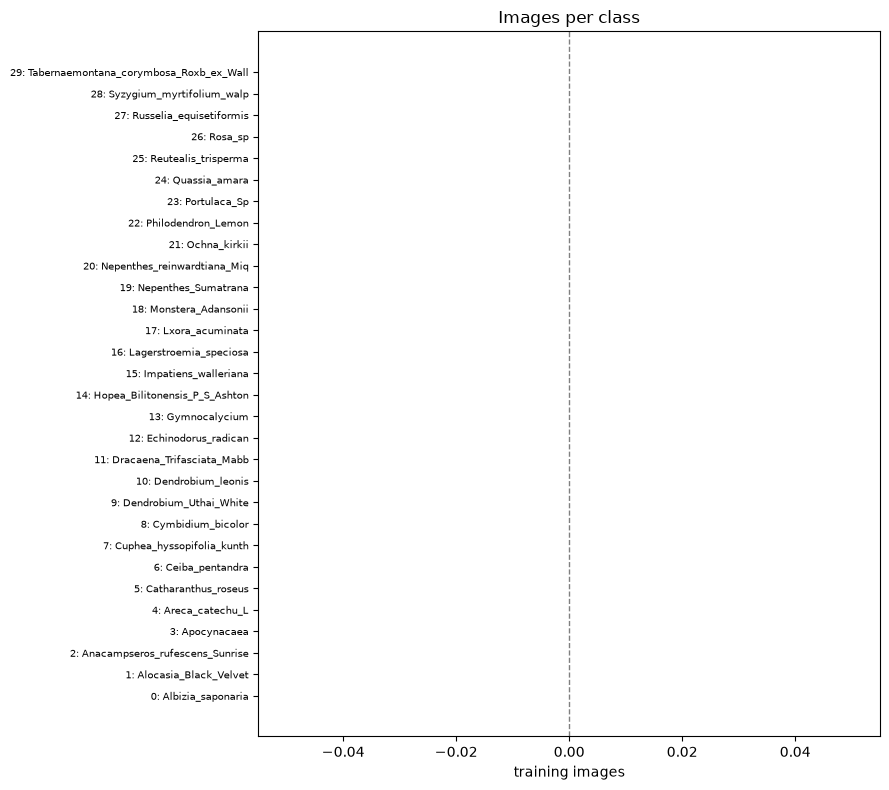

In [7]:
counts = files["label"].value_counts().reindex(range(NUM_CLASSES), fill_value=0)
bal = pd.DataFrame({"species": [SPECIES[i] for i in counts.index], "n": counts.values}, index=counts.index)
bal["share_%"] = (100 * bal["n"] / bal["n"].sum()).round(2)
display(bal.sort_values("n"))

nz = counts[counts > 0]
ratio = nz.max() / nz.min() if len(nz) else np.nan
print(f"total {counts.sum():,} | min {counts.min()} | median {int(counts.median())} | max {counts.max()} | max/min {ratio:.1f}")

if (counts == 0).any():
    flag("BLOCKER", f"Classes with zero training images: {counts[counts == 0].index.tolist()}")
if ratio > 3:
    flag("WARN", f"Class imbalance max/min = {ratio:.1f}. Use class-weighted loss or a balanced sampler; "
                 f"smallest: {bal.sort_values('n').head(3)['species'].tolist()}")
else:
    flag("INFO", f"Classes are fairly balanced (max/min = {ratio:.1f}).")
N_SPLITS = int(max(2, min(5, counts[counts > 0].min())))
if counts[counts > 0].min() < 25:
    flag("WARN", f"Smallest class has {counts[counts > 0].min()} images: per-class F1 per fold will be noisy; "
                 f"use {N_SPLITS}-fold stratified CV and average, or repeated CV.")

fig, ax = plt.subplots(figsize=(9, 8))
order = bal.sort_values("n")
ax.barh([f"{i}: {s}" for i, s in zip(order.index, order["species"])], order["n"], color="#4C8C4A")
ax.axvline(order["n"].median(), ls="--", c="grey", lw=1)
ax.set_xlabel("training images"); ax.set_title("Images per class")
ax.tick_params(axis="y", labelsize=7)
savefig("01_class_balance")

## 5. Image scan

One pass over every train and test image (threaded). For each file it records format, colour mode, size, EXIF orientation / timestamp / camera, MD5, colour statistics, sharpness (Laplacian variance), a 64-bit difference hash for duplicate search, and a small hand-crafted feature vector (HSV colour histogram, 4×4 colour grid, 4×4×8 gradient-orientation histogram) used later for the signal floor and adversarial validation.

JPEGs are decoded at reduced resolution (`draft`) so the scan stays fast even for 12 MP photos.

In [8]:
HUE_BINS, SAT_BINS, VAL_BINS = 18, 3, 3
N_HSV = HUE_BINS * SAT_BINS * VAL_BINS
CLS   = slice(0, N_HSV + 48 + 128)                  # features used by the classifiers (HSV hist + colour grid + HOG-lite)
GRID  = slice(N_HSV, N_HSV + 48)                    # 4x4 mean-RGB grid
THUMB = slice(N_HSV + 48 + 128, N_HSV + 48 + 128 + 256)   # z-scored 16x16 thumbnail (duplicate check only)

def hog_lite(g):  # g: 64x64 float gray
    gx = np.zeros_like(g); gy = np.zeros_like(g)
    gx[:, 1:-1] = g[:, 2:] - g[:, :-2]
    gy[1:-1, :] = g[2:, :] - g[:-2, :]
    mag = np.hypot(gx, gy)
    ang = np.mod(np.arctan2(gy, gx), np.pi)
    b = np.minimum((ang / np.pi * 8).astype(int), 7)
    rr, cc = np.indices(g.shape)
    cell = (rr // 16) * 4 + (cc // 16)
    h = np.bincount((cell * 8 + b).ravel(), weights=mag.ravel(), minlength=128)
    return h / (np.linalg.norm(h) + 1e-8)

def probe_image(path):
    r = {"path": path}
    try:
        raw = Path(path).read_bytes()
        r["bytes"] = len(raw)
        r["md5"] = hashlib.md5(raw).hexdigest()
        with Image.open(io.BytesIO(raw)) as im:
            r["format"], r["mode"] = im.format, im.mode
            r["width"], r["height"] = im.size
            r["n_frames"] = getattr(im, "n_frames", 1)
            r["icc"] = "icc_profile" in im.info
            ex = im.getexif()
            r["exif_orient"] = int(ex.get(274, 1) or 1)
            cam = " ".join(str(ex.get(t, "")).strip("\x00 ") for t in (271, 272)).strip()
            r["camera"] = cam or None
            dt = ex.get(306)
            try:
                dt = ex.get_ifd(0x8769).get(36867, dt)
            except Exception:
                pass
            r["exif_dt"] = str(dt).strip("\x00 ") if dt else None
            im.draft("RGB", (256, 256))
            im = ImageOps.exif_transpose(im)
            if im.mode in ("RGBA", "LA", "P"):
                im = im.convert("RGBA")
                bg = Image.new("RGBA", im.size, (255, 255, 255, 255))
                im = Image.alpha_composite(bg, im)
            im = im.convert("RGB").resize((128, 128), Image.BILINEAR)
        a = np.asarray(im, dtype=np.float32) / 255.0
        gray = a @ np.array([0.299, 0.587, 0.114], dtype=np.float32)
        hsv = np.asarray(im.convert("HSV"), dtype=np.int32)
        lap = (-4 * gray[1:-1, 1:-1] + gray[:-2, 1:-1] + gray[2:, 1:-1] + gray[1:-1, :-2] + gray[1:-1, 2:]) * 255
        r.update(mean_r=a[..., 0].mean(), mean_g=a[..., 1].mean(), mean_b=a[..., 2].mean(),
                 std_rgb=a.std(), brightness=gray.mean(), contrast=gray.std(),
                 saturation=hsv[..., 1].mean() / 255, blur_lapvar=float(lap.var()),
                 green_frac=float(((hsv[..., 0] >= 42) & (hsv[..., 0] <= 120) & (hsv[..., 1] > 50) & (hsv[..., 2] > 40)).mean()),
                 is_gray=float(np.abs(a[..., 0] - a[..., 1]).mean() + np.abs(a[..., 1] - a[..., 2]).mean()) < 0.01)
        g9 = np.asarray(im.convert("L").resize((9, 8), Image.BILINEAR), dtype=np.int16)
        r["dhash"] = np.packbits((g9[:, 1:] > g9[:, :-1]).ravel()).tobytes().hex()
        hb = (hsv[..., 0] * HUE_BINS // 256) * SAT_BINS * VAL_BINS + (hsv[..., 1] * SAT_BINS // 256) * VAL_BINS + (hsv[..., 2] * VAL_BINS // 256)
        hist = np.bincount(hb.ravel(), minlength=HUE_BINS * SAT_BINS * VAL_BINS) / hb.size
        grid = a.reshape(4, 32, 4, 32, 3).mean(axis=(1, 3)).ravel()
        g64 = np.asarray(im.convert("L").resize((64, 64), Image.BILINEAR), dtype=np.float32) / 255
        t16 = np.asarray(im.convert("L").resize((16, 16), Image.BILINEAR), dtype=np.float32).ravel()
        t16 = (t16 - t16.mean()) / (t16.std() + 1e-6)   # z-scored 16x16 gray thumbnail, only for duplicate checks
        feat = np.concatenate([hist, grid, hog_lite(g64), t16]).astype(np.float32)
        r["ok"] = True
        return r, feat
    except Exception as e:
        r["ok"] = False
        r["error"] = f"{type(e).__name__}: {e}"[:200]
        return r, None

def scan(paths, tag):
    paths = list(paths)
    if MAX_IMAGES and len(paths) > MAX_IMAGES:
        rng = np.random.default_rng(SEED)
        paths = sorted(rng.choice(paths, MAX_IMAGES, replace=False).tolist())
    rows, feats, t0 = [None] * len(paths), [None] * len(paths), time.time()
    step = max(1, len(paths) // 10)
    with ThreadPoolExecutor(N_WORKERS) as ex:
        for i, (r, f) in enumerate(ex.map(probe_image, paths)):
            rows[i], feats[i] = r, f
            if (i + 1) % step == 0 or i + 1 == len(paths):
                print(f"  {tag}: {i + 1:,}/{len(paths):,}  ({time.time() - t0:.0f}s)")
    df = pd.DataFrame(rows)
    df["split"] = tag
    return df, feats

S_tr, F_tr = scan(files["path"], "train")
S_te, F_te = scan(test_files["path"], "test") if len(test_files) else (pd.DataFrame(columns=["path", "ok"]), [])

FEAT = {p: f for p, f in zip(S_tr["path"], F_tr) if f is not None}
FEAT.update({p: f for p, f in zip(S_te["path"], F_te) if f is not None})
S_tr = S_tr.merge(files[["path", "rel", "label", "species"]], on="path", how="left")
S = pd.concat([S_tr, S_te], ignore_index=True)
for c in ["width", "height", "bytes"]:
    if c in S:
        S[c] = pd.to_numeric(S[c], errors="coerce")
S["aspect"] = S["width"] / S["height"]
S["megapix"] = S["width"] * S["height"] / 1e6
S["bytes_per_px"] = S["bytes"] / (S["width"] * S["height"])
S["orientation"] = np.select([S["aspect"] > 1.05, S["aspect"] < 0.95], ["landscape", "portrait"], "square")
S.drop(columns=[]).to_csv(OUT_DIR / "image_stats.csv", index=False)
print("saved", OUT_DIR / "image_stats.csv")

KeyError: 'path'

## 6. File integrity

In [ ]:
bad = S[~S["ok"].astype(bool)]
if len(bad):
    for split, g in bad.groupby("split"):
        lvl = "BLOCKER" if split == "test" else "WARN"
        flag(lvl, f"{len(g)} unreadable {split} images, e.g. {g[['path', 'error']].head(3).values.tolist()}"
                  + (" — the inference loop must not crash on these; predict a fallback class." if split == "test"
                     else " — drop them from training."))
else:
    print("every image decodes cleanly")

good = S[S["ok"].astype(bool)].copy()
good["ext"] = good["path"].map(lambda p: Path(p).suffix.lower().lstrip("."))
ext_map = {"jpg": "JPEG", "jpeg": "JPEG", "png": "PNG", "bmp": "BMP", "webp": "WEBP", "tif": "TIFF", "tiff": "TIFF", "gif": "GIF"}
wrong_ext = good[good["ext"].map(ext_map) != good["format"]]
if len(wrong_ext):
    flag("INFO", f"{len(wrong_ext)} files whose extension does not match the real format "
                 f"({dict(Counter(zip(wrong_ext['ext'], wrong_ext['format'])))}). PIL handles this; some loaders do not.")

print("\ncolour modes:")
display(pd.crosstab(good["mode"], good["split"]))
if (good["mode"] != "RGB").any():
    flag("WARN", f"{(good['mode'] != 'RGB').sum()} images are not RGB ({dict(Counter(good.loc[good['mode'] != 'RGB', 'mode']))}). "
                 "Always .convert('RGB') in the loader (RGBA/P/L would otherwise break the 3-channel input).")

rot = good[good["exif_orient"] != 1]
if len(rot):
    by = dict(Counter(rot["split"]))
    flag("WARN", f"{len(rot)} images carry an EXIF rotation tag ({by}). PIL ignores it unless you call "
                 "ImageOps.exif_transpose; OpenCV applies it. Pick one and use it for train AND test.")
if (good.get("n_frames", 1) > 1).any():
    flag("INFO", f"{(good['n_frames'] > 1).sum()} multi-frame images (only the first frame is used).")
tiny = good[np.minimum(good["width"], good["height"]) < 64]
if len(tiny):
    flag("WARN", f"{len(tiny)} images smaller than 64 px on the short side.")
if good["is_gray"].astype(bool).any():
    flag("INFO", f"{good['is_gray'].astype(bool).sum()} images are effectively grayscale ({dict(Counter(good.loc[good['is_gray'].astype(bool), 'split']))}).")

## 7. Geometry: sizes, aspect ratios, file sizes

If one class is always shot portrait or at a particular resolution, a CNN can learn that instead of the plant. The *metadata-only* classifier at the end of this section measures how much class information leaks through size alone.

In [ ]:
def ks_stat(a, b):
    a, b = np.sort(np.asarray(a, float)), np.sort(np.asarray(b, float))
    if len(a) == 0 or len(b) == 0:
        return np.nan
    v = np.concatenate([a, b])
    return float(np.max(np.abs(np.searchsorted(a, v, "right") / len(a) - np.searchsorted(b, v, "right") / len(b))))

geo_cols = ["width", "height", "aspect", "megapix", "bytes", "bytes_per_px"]
display(good.groupby("split")[geo_cols].describe(percentiles=[.05, .5, .95]).T.round(3))

print("most common (width x height):")
good["wxh"] = good["width"].astype(int).astype(str) + "x" + good["height"].astype(int).astype(str)
display(pd.crosstab(good["wxh"], good["split"], normalize="columns").mul(100).round(1)
        .sort_values("train", ascending=False).head(10))
print("orientation share (%):")
display(pd.crosstab(good["orientation"], good["split"], normalize="columns").mul(100).round(1))

g_tr = good[(good["split"] == "train") & good["label"].notna()].reset_index(drop=True)
g_tr["label"] = g_tr["label"].astype(int)
g_te = good[good["split"] == "test"].reset_index(drop=True)
FEAT_TR = np.stack([FEAT[p] for p in g_tr["path"]])
FEAT_TE = np.stack([FEAT[p] for p in g_te["path"]]) if len(g_te) else np.zeros((0, FEAT_TR.shape[1]), np.float32)
if len(g_te):
    shift = {c: round(ks_stat(g_tr[c], g_te[c]), 3) for c in geo_cols}
    print("KS distance train vs test:", shift)
    big = {k: v for k, v in shift.items() if v > 0.15}
    if big:
        flag("WARN", f"Train/test geometry differs (KS > 0.15): {big}. Normalise size with resize/crop, "
                     "and make sure augmentation covers the test aspect ratios.")

fig, axs = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, c, lg in zip(axs, ["megapix", "aspect", "bytes_per_px"], [False, False, False]):
    for split, col in [("train", "#4C8C4A"), ("test", "#D98E04")]:
        v = good.loc[good["split"] == split, c].dropna()
        if len(v):
            ax.hist(v, bins=40, alpha=.55, density=True, label=split, color=col)
    ax.set_title(c); ax.legend()
savefig("02_geometry_train_vs_test")

per_class_geo = g_tr.groupby("label").agg(
    species=("species", "first"), n=("path", "size"),
    med_w=("width", "median"), med_h=("height", "median"),
    portrait_pct=("orientation", lambda s: round(100 * (s == "portrait").mean(), 1)),
    med_kb=("bytes", lambda s: round(s.median() / 1024)),
    distinct_sizes=("wxh", "nunique"))
display(per_class_geo)

In [ ]:
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold, cross_val_predict
from sklearn.metrics import f1_score, accuracy_score, roc_auc_score, confusion_matrix

meta_cols = ["width", "height", "aspect", "megapix", "bytes", "bytes_per_px", "exif_orient"]
Xm = g_tr[meta_cols].fillna(-1).values
ym = g_tr["label"].values
skf = StratifiedKFold(N_SPLITS, shuffle=True, random_state=SEED)
pm = cross_val_predict(RandomForestClassifier(300, random_state=SEED, n_jobs=-1, class_weight="balanced"), Xm, ym, cv=skf)
meta_f1 = f1_score(ym, pm, average="macro")
majority_f1 = f1_score(ym, np.full_like(ym, np.bincount(ym).argmax()), average="macro")
print(f"metadata-only Macro F1 = {meta_f1:.3f}   (always-majority baseline {majority_f1:.3f}, random ≈ {1 / NUM_CLASSES:.3f})")
if meta_f1 > 0.25:
    flag("WARN", f"Image size / file size alone predicts the class with Macro F1 {meta_f1:.2f}. "
                 "A CNN can shortcut on this; resize to a fixed square input (random-resized-crop) and check "
                 "that test sizes look like train sizes before trusting CV.")
else:
    flag("INFO", f"Size/file-size metadata carries little class signal (Macro F1 {meta_f1:.2f}).")

## 8. Colour, lighting and sharpness

Per-class distributions in train, plus train-vs-test comparisons. Large train/test differences in brightness or blur suggest different capture sessions, which colour/blur augmentation should cover.

In [ ]:
qcols = ["brightness", "contrast", "saturation", "green_frac", "blur_lapvar"]
display(good.groupby("split")[qcols].describe(percentiles=[.05, .5, .95]).T.round(3))
if len(g_te):
    qshift = {c: round(ks_stat(g_tr[c], g_te[c]), 3) for c in qcols}
    print("KS distance train vs test:", qshift)
    big = {k: v for k, v in qshift.items() if v > 0.15}
    if big:
        flag("WARN", f"Train/test colour or sharpness differs (KS > 0.15): {big}. Add matching colour-jitter / blur augmentation.")

blur_cut = np.percentile(g_tr["blur_lapvar"], 5)
print(f"\n5th percentile Laplacian variance in train: {blur_cut:.1f}  (lower = blurrier)")

fig, axs = plt.subplots(len(qcols), 1, figsize=(14, 2.6 * len(qcols)), sharex=True)
order = sorted(g_tr["label"].unique())
for ax, c in zip(axs, qcols):
    data = [np.log10(g_tr.loc[g_tr["label"] == k, c] + 1) if c == "blur_lapvar" else g_tr.loc[g_tr["label"] == k, c] for k in order]
    ax.boxplot(data, showfliers=False)
    ax.set_ylabel("log10 " + c if c == "blur_lapvar" else c, fontsize=8)
axs[-1].set_xticks(range(1, len(order) + 1))
axs[-1].set_xticklabels([f"{k}" for k in order], fontsize=8)
axs[-1].set_xlabel("class label")
savefig("03_colour_sharpness_per_class")

fig, axs = plt.subplots(1, len(qcols), figsize=(18, 3.2))
for ax, c in zip(axs, qcols):
    for split, col in [("train", "#4C8C4A"), ("test", "#D98E04")]:
        v = good.loc[good["split"] == split, c]
        v = np.log10(v + 1) if c == "blur_lapvar" else v
        if len(v):
            ax.hist(v, bins=40, alpha=.55, density=True, label=split, color=col)
    ax.set_title(("log10 " if c == "blur_lapvar" else "") + c); ax.legend(fontsize=7)
savefig("04_colour_sharpness_train_vs_test")

In [ ]:
has_dt = g_tr["exif_dt"].notna().mean()
has_cam = g_tr["camera"].notna().mean()
print(f"EXIF timestamp present: train {has_dt:.0%}" + (f", test {g_te['exif_dt'].notna().mean():.0%}" if len(g_te) else ""))
print(f"camera make/model present: train {has_cam:.0%}")
if has_cam > 0:
    display(pd.crosstab(good["camera"].fillna("(none)"), good["split"]).sort_values("train", ascending=False).head(10))
if has_dt > 0.3:
    g_tr["shoot_day"] = g_tr["exif_dt"].str.slice(0, 10)
    days = g_tr.groupby("label")["shoot_day"].nunique()
    print("\nshooting days per class:", days.describe().round(2).to_dict())
    one_day = (days <= 1).mean()
    if one_day > 0.5:
        flag("WARN", f"{one_day:.0%} of classes were photographed on a single day. Background/lighting of that "
                     "session can act as a shortcut; strong colour + crop augmentation helps.")
    if g_tr["camera"].nunique() > 1:
        cam_cls = pd.crosstab(g_tr["label"], g_tr["camera"].fillna("(none)"))
        purity = (cam_cls.max(axis=1) / cam_cls.sum(axis=1)).mean()
        print(f"mean share of the dominant camera per class: {purity:.0%}")

## 9. Training images per class (visual check)

Six random training images per class. Only training images are shown.

In [ ]:
def thumb(path, size=112):
    try:
        with Image.open(path) as im:
            im.draft("RGB", (size * 2, size * 2))
            im = ImageOps.exif_transpose(im).convert("RGB")
            im = ImageOps.fit(im, (size, size))
            return np.asarray(im)
    except Exception:
        return np.zeros((size, size, 3), np.uint8)

PER = 6
labels_present = sorted(g_tr["label"].unique())
fig, axs = plt.subplots(len(labels_present), PER, figsize=(PER * 1.3, len(labels_present) * 1.35))
axs = np.atleast_2d(axs)
for r, k in enumerate(labels_present):
    pool = g_tr[g_tr["label"] == k]["path"].tolist()
    pick = random.Random(SEED + int(k)).sample(pool, min(PER, len(pool)))
    for c in range(PER):
        ax = axs[r, c]; ax.axis("off")
        if c < len(pick):
            ax.imshow(thumb(pick[c]))
    axs[r, 0].text(-8, 56, f"{k}: {SPECIES[k][:22]}", ha="right", va="center", fontsize=7)
plt.subplots_adjust(wspace=.03, hspace=.05)
plt.savefig(OUT_DIR / "05_class_montage.png", dpi=110, bbox_inches="tight")
plt.show()

## 10. Exact and near-duplicates

- **Exact**: identical MD5.
- **Near**: 64-bit difference hash within Hamming distance `NEAR_T`, confirmed by a matching 4×4 colour layout (`COLOR_T`) and a correlated 16×16 thumbnail (`CORR_T`) — catches re-saved, resized or burst shots. Candidate pairs come from 8 hash bands (any pair within 7 bits shares at least one band), then both conditions are verified. Loosen the thresholds to catch more, tighten to cut false positives.

Why it matters: duplicates split across CV folds make CV optimistic; duplicates **across classes** are label noise. Train↔test overlap is reported **only as a count** — it tells you how much CV and the leaderboard can disagree; it is not used to label test images.

In [ ]:
POP = np.array([bin(i).count("1") for i in range(256)], dtype=np.uint8)

COLOR_T = 0.05   # max mean absolute difference of the 4x4 colour grid (0..1)
CORR_T  = 0.90   # min correlation of the 16x16 gray thumbnails

def near_pairs(hex_hashes, feats, max_d=NEAR_T, bucket_cap=3000):
    # dHash candidates within max_d bits, confirmed by colour layout and thumbnail correlation
    # (dHash alone over-matches flat, low-texture images).
    H = np.array([np.frombuffer(bytes.fromhex(h), dtype=np.uint8) for h in hex_hashes]) if len(hex_hashes) else np.zeros((0, 8), np.uint8)
    n = len(H)
    cand = []
    for b in range(8):
        col = H[:, b]
        order = np.argsort(col, kind="stable")
        vals, starts, cnts = np.unique(col[order], return_index=True, return_counts=True)
        for s, c in zip(starts, cnts):
            if c < 2:
                continue
            idx = order[s:s + c][:bucket_cap]
            i, j = np.triu_indices(len(idx), 1)
            cand.append(np.stack([idx[i], idx[j]], 1))
    if not cand:
        return pd.DataFrame(columns=["i", "j", "d"])
    P = np.unique(np.sort(np.concatenate(cand), 1), axis=0)
    d = POP[np.bitwise_xor(H[P[:, 0]], H[P[:, 1]])].sum(1)
    cdiff = np.abs(feats[P[:, 0], GRID] - feats[P[:, 1], GRID]).mean(1)
    corr = (feats[P[:, 0], THUMB] * feats[P[:, 1], THUMB]).mean(1)
    keep = (d <= max_d) & (cdiff < COLOR_T) & (corr > CORR_T)
    return pd.DataFrame({"i": P[keep, 0], "j": P[keep, 1], "d": d[keep],
                         "cdiff": cdiff[keep].round(4), "corr": corr[keep].round(3)})

class UF:
    def __init__(s, n): s.p = list(range(n))
    def f(s, x):
        while s.p[x] != x:
            s.p[x] = s.p[s.p[x]]; x = s.p[x]
        return x
    def u(s, a, b): s.p[s.f(a)] = s.f(b)

# --- within train ---
exact_groups = g_tr.groupby("md5")["path"].transform("size")
n_exact = int((exact_groups > 1).sum())
pairs = near_pairs(g_tr["dhash"].tolist(), FEAT_TR)
pairs["exact"] = g_tr["md5"].values[pairs["i"]] == g_tr["md5"].values[pairs["j"]]
pairs["li"], pairs["lj"] = g_tr["label"].values[pairs["i"]], g_tr["label"].values[pairs["j"]]
cross = pairs[pairs["li"] != pairs["lj"]]

uf = UF(len(g_tr))
for a, b in zip(pairs["i"], pairs["j"]):
    uf.u(int(a), int(b))
for _, grp in g_tr.groupby("md5").groups.items():
    grp = list(grp)
    for x in grp[1:]:
        uf.u(grp[0], x)
g_tr["dup_group"] = [uf.f(i) for i in range(len(g_tr))]
gsize = g_tr["dup_group"].map(g_tr["dup_group"].value_counts())
in_dup = int((gsize > 1).sum())

print(f"train images in an exact-duplicate set : {n_exact}")
print(f"near-duplicate pairs (d<={NEAR_T})       : {len(pairs)}  -> {in_dup} images ({in_dup / len(g_tr):.1%}) belong to a duplicate cluster")
print(f"cross-class near-duplicate pairs        : {len(cross)}")
print("pairs by distance:", dict(sorted(Counter(pairs['d']).items())))

if in_dup / max(1, len(g_tr)) > 0.02:
    flag("WARN", f"{in_dup / len(g_tr):.1%} of train images have a near-duplicate. Use StratifiedGroupKFold with "
                 f"the dup_group column (saved to train_groups.csv) or CV will be optimistic.")
if len(cross):
    tops = cross.head(10).apply(lambda r: f"{g_tr.at[r.i, 'rel']} ({SPECIES[r.li]}) ~ {g_tr.at[r.j, 'rel']} ({SPECIES[r.lj]}) d={r.d}", axis=1).tolist()
    flag("WARN", f"{len(cross)} near-duplicate pairs carry DIFFERENT labels (label noise or a mis-filed image). "
                 f"First ones: {tops[:3]}")

g_tr[["rel", "label", "dup_group"]].to_csv(OUT_DIR / "train_groups.csv", index=False)
print("saved", OUT_DIR / "train_groups.csv")

# --- train <-> test (counts only) ---
if len(g_te):
    allh = g_tr["dhash"].tolist() + g_te["dhash"].tolist()
    ntr = len(g_tr)
    pp = near_pairs(allh, np.vstack([FEAT_TR, FEAT_TE]))
    pp = pp[(pp["i"] < ntr) != (pp["j"] < ntr)]
    te_idx = np.where(pp["i"] >= ntr, pp["i"], pp["j"]) - ntr
    n_te_near = len(set(te_idx))
    n_te_exact = int(g_te["md5"].isin(set(g_tr["md5"])).sum())
    print(f"\ntest images with an exact copy in train : {n_te_exact} ({n_te_exact / len(g_te):.1%})")
    print(f"test images with a near-duplicate in train: {n_te_near} ({n_te_near / len(g_te):.1%})")
    if n_te_near / len(g_te) > 0.05:
        flag("INFO", f"{n_te_near / len(g_te):.0%} of test images closely resemble a train image: the leaderboard "
                     "will partly reward memorisation, so non-grouped CV may match LB better than grouped CV. Track both.")

In [ ]:
# Show up to 8 cross-class near-duplicate pairs (training images only).
show = cross.sort_values("d").head(8)
if len(show):
    fig, axs = plt.subplots(len(show), 2, figsize=(4.2, 2.1 * len(show)))
    axs = np.atleast_2d(axs)
    for r, row in enumerate(show.itertuples()):
        for c, (ii, ll) in enumerate([(row.i, row.li), (row.j, row.lj)]):
            axs[r, c].imshow(thumb(g_tr.at[ii, "path"], 160)); axs[r, c].axis("off")
            axs[r, c].set_title(f"{ll}: {SPECIES[ll][:18]}\n{g_tr.at[ii, 'rel'].split('/')[-1]}  d={row.d}", fontsize=7)
    plt.tight_layout(); plt.savefig(OUT_DIR / "06_cross_class_duplicates.png", dpi=110); plt.show()
else:
    print("no cross-class near-duplicates to show")

## 11. Adversarial validation (train vs test)

A classifier is asked to tell train images from test images using only the scan statistics and colour/gradient features. **AUC ≈ 0.5** means test looks like train and CV should transfer to the leaderboard; **AUC > 0.7** means a shift worth handling (augmentation, normalisation, or a CV split that mimics test). Test labels are never involved.

In [ ]:
from sklearn.metrics import roc_auc_score

scalar_cols = ["width", "height", "aspect", "megapix", "bytes_per_px", "mean_r", "mean_g", "mean_b",
               "std_rgb", "brightness", "contrast", "saturation", "green_frac", "blur_lapvar", "exif_orient"]

ADV_AUC = None
if len(g_te) >= 20:
    Xa = np.vstack([np.hstack([g_tr[scalar_cols].fillna(-1).values, FEAT_TR[:, CLS]]),
                    np.hstack([g_te[scalar_cols].fillna(-1).values, FEAT_TE[:, CLS]])])
    ya = np.r_[np.zeros(len(g_tr)), np.ones(len(g_te))]
    names = scalar_cols + [f"hsv{i}" for i in range(HUE_BINS * SAT_BINS * VAL_BINS)] + [f"grid{i}" for i in range(48)] + [f"hog{i}" for i in range(128)]
    rf = RandomForestClassifier(300, min_samples_leaf=3, random_state=SEED, n_jobs=-1, class_weight="balanced")
    pa = cross_val_predict(rf, Xa, ya, cv=StratifiedKFold(5, shuffle=True, random_state=SEED), method="predict_proba")[:, 1]
    ADV_AUC = roc_auc_score(ya, pa)
    rf.fit(Xa, ya)
    imp = pd.Series(rf.feature_importances_, index=names).sort_values(ascending=False).head(12)
    print(f"adversarial AUC = {ADV_AUC:.3f}")
    display(imp.round(4).to_frame("importance"))
    if ADV_AUC > 0.85:
        flag("WARN", f"Strong train/test shift (adversarial AUC {ADV_AUC:.2f}); top separating features: {imp.index[:5].tolist()}.")
    elif ADV_AUC > 0.70:
        flag("WARN", f"Moderate train/test shift (adversarial AUC {ADV_AUC:.2f}); top separating features: {imp.index[:5].tolist()}.")
    else:
        flag("INFO", f"Train and test look alike (adversarial AUC {ADV_AUC:.2f}); CV should track the leaderboard.")
    # Train images that look most "test-like" are a reasonable hold-out set for model selection.
    g_tr["testlike_score"] = pa[:len(g_tr)]
    g_tr[["rel", "label", "testlike_score"]].sort_values("testlike_score", ascending=False) \
        .to_csv(OUT_DIR / "train_testlikeness.csv", index=False)
else:
    print("not enough test images for adversarial validation")

## 12. From-scratch signal floor

Two classical models on the hand-crafted features (no pretrained weights anywhere). They give:
- a **floor** Macro F1 that a from-scratch CNN should clearly beat;
- the **gap between plain stratified CV and grouped CV** (duplicates kept in one fold) — a large gap means duplicates inflate CV;
- the **hardest classes and most-confused pairs**, which is where augmentation, resolution and class weights pay off.

In [ ]:
X = FEAT_TR[:, CLS]
y = g_tr["label"].values
groups = g_tr["dup_group"].values

models = {
    "LogReg (HSV+grid+HOG)": make_pipeline(StandardScaler(), LogisticRegression(C=0.5, max_iter=3000, class_weight="balanced")),
    "ExtraTrees (HSV+grid+HOG)": ExtraTreesClassifier(500, min_samples_leaf=1, class_weight="balanced", random_state=SEED, n_jobs=-1),
}
cvs = {"stratified": StratifiedKFold(N_SPLITS, shuffle=True, random_state=SEED)}
if len(set(groups)) < len(groups):
    cvs["grouped (dups together)"] = StratifiedGroupKFold(N_SPLITS, shuffle=True, random_state=SEED)

rows, preds = [], {}
for mname, m in models.items():
    for cname, cv in cvs.items():
        t0 = time.time()
        p = cross_val_predict(m, X, y, cv=cv, groups=groups if "grouped" in cname else None)
        preds[(mname, cname)] = p
        rows.append(dict(model=mname, cv=cname, macro_f1=f1_score(y, p, average="macro"),
                         accuracy=accuracy_score(y, p), seconds=round(time.time() - t0, 1)))
res = pd.DataFrame(rows).round(4)
display(res)

best = res.sort_values("macro_f1", ascending=False).iloc[0]
FLOOR = float(best["macro_f1"])
flag("INFO", f"Hand-crafted signal floor: Macro F1 {FLOOR:.3f} ({best['model']}, {best['cv']} CV, {N_SPLITS} folds). "
             "A from-scratch CNN that does not beat this has a pipeline bug.")
if len(cvs) > 1:
    for mname in models:
        a = res[(res.model == mname) & (res.cv == "stratified")]["macro_f1"].iloc[0]
        b = res[(res.model == mname) & (res.cv != "stratified")]["macro_f1"].iloc[0]
        if a - b > 0.03:
            flag("WARN", f"{mname}: stratified CV {a:.3f} vs grouped CV {b:.3f}. Duplicates inflate plain CV by {a - b:.3f}.")

In [ ]:
key = (best["model"], best["cv"])
p = preds[key]
per = pd.DataFrame({"species": [SPECIES[k] for k in range(NUM_CLASSES)],
                    "n": np.bincount(y, minlength=NUM_CLASSES),
                    "f1": f1_score(y, p, average=None, labels=list(range(NUM_CLASSES)), zero_division=0)}).round(3)
print("Per-class F1 (hardest first):")
display(per.sort_values("f1").head(12))

cmx = confusion_matrix(y, p, labels=list(range(NUM_CLASSES)))
off = cmx.copy(); np.fill_diagonal(off, 0)
pair = [(off[i, j] + off[j, i], i, j) for i in range(NUM_CLASSES) for j in range(i + 1, NUM_CLASSES) if off[i, j] + off[j, i] > 0]
pair = sorted(pair, reverse=True)[:10]
print("Most confused class pairs (both directions):")
display(pd.DataFrame([(n, f"{i}: {SPECIES[i]}", f"{j}: {SPECIES[j]}") for n, i, j in pair], columns=["errors", "class A", "class B"]))

fig, ax = plt.subplots(figsize=(8.5, 7.5))
norm = cmx / cmx.sum(1, keepdims=True).clip(min=1)
im = ax.imshow(norm, cmap="Greens", vmin=0, vmax=1)
ax.set_xticks(range(NUM_CLASSES)); ax.set_yticks(range(NUM_CLASSES))
ax.set_xticklabels(range(NUM_CLASSES), fontsize=7); ax.set_yticklabels([f"{k} {SPECIES[k][:16]}" for k in range(NUM_CLASSES)], fontsize=7)
ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(f"Row-normalised confusion — {key[0]}")
plt.colorbar(im, fraction=.04)
savefig("07_confusion_floor")
per.to_csv(OUT_DIR / "per_class_floor_f1.csv", index_label="label")

## 13. Summary and recommendations

Everything flagged above, grouped by severity, plus recommendations derived from what was found. Written to `probe_out/probe_report.md` and `probe_out/probe_summary.json`.

In [ ]:
n_tr, n_te = len(files), len(test_files)
summary = {
    "data_root": str(ROOT), "train_images": n_tr, "test_images": n_te, "classes": NUM_CLASSES,
    "min_class": int(counts.min()), "max_class": int(counts.max()), "imbalance_ratio": round(float(ratio), 2),
    "unreadable": int(len(bad)), "non_rgb": int((good["mode"] != "RGB").sum()),
    "exif_rotated": int(len(rot)), "train_in_dup_cluster": in_dup, "cross_class_dup_pairs": int(len(cross)),
    "metadata_only_macro_f1": round(meta_f1, 4), "adversarial_auc": None if ADV_AUC is None else round(ADV_AUC, 4),
    "floor_macro_f1": round(FLOOR, 4), "n_splits": N_SPLITS,
}

recs = []
recs.append(f"Validate with {N_SPLITS}-fold " + ("StratifiedGroupKFold on dup_group (probe_out/train_groups.csv)" if in_dup else "StratifiedKFold")
            + f", seed {SEED}; report Macro F1, not accuracy.")
if ratio > 3:
    recs.append("Imbalance: class-weighted cross-entropy (weights ∝ 1/sqrt(n) or 1/n) or a class-balanced sampler; "
                "check per-class recall of the smallest classes every epoch.")
recs.append("Loader: Image.open → ImageOps.exif_transpose → convert('RGB') for train AND test; wrap in try/except and "
            "fall back to a black image so inference never crashes.")
if meta_f1 > 0.25:
    recs.append("Size leaks class information: train on fixed-size square crops (RandomResizedCrop) so the model cannot read aspect ratio.")
if ADV_AUC is not None and ADV_AUC > 0.7:
    recs.append("Train/test shift: add colour-jitter/blur/scale augmentation matched to the separating features, and "
                "select checkpoints on the most test-like train images (probe_out/train_testlikeness.csv).")
if len(cross):
    recs.append(f"Review the {len(cross)} cross-class duplicate pairs (06_cross_class_duplicates.png); drop or keep one "
                "copy only after deciding which label is right from the training data itself.")
recs.append(f"Every from-scratch model must beat the hand-crafted floor (Macro F1 {FLOOR:.3f}).")
recs.append("Rules: weights=None / pretrained=False for every architecture; no external data, VLMs or AutoML; "
            "fix seeds for random/numpy/torch (+ cudnn.deterministic); never inspect or hand-label test images.")
recs.append("Submission: build from sample_submission (keep id order), integer labels 0..%d, then run check_submission()." % (NUM_CLASSES - 1))

order_lvl = {"BLOCKER": 0, "WARN": 1, "INFO": 2}
fsorted = sorted(FINDINGS, key=lambda t: order_lvl.get(t[0], 3))
lines = ["# DATERAQUEST 2.0 — data probe report", "",
         f"Data root: `{ROOT}`", "",
         "| item | value |", "|---|---|"] + [f"| {k} | {v} |" for k, v in summary.items()] + ["", "## Findings", ""]
for lvl in ["BLOCKER", "WARN", "INFO"]:
    items = [m for l, m in fsorted if l == lvl]
    if items:
        lines += [f"### {lvl} ({len(items)})", ""] + [f"- {m}" for m in items] + [""]
lines += ["## Recommendations", ""] + [f"{i}. {r}" for i, r in enumerate(recs, 1)] + [""]
lines += ["## Files written", ""] + [f"- `{p.name}`" for p in sorted(OUT_DIR.iterdir())]
(OUT_DIR / "probe_report.md").write_text("\n".join(lines), encoding="utf-8")
(OUT_DIR / "probe_summary.json").write_text(json.dumps({"summary": summary, "findings": fsorted, "recommendations": recs}, indent=2, default=str), encoding="utf-8")

from IPython.display import Markdown
display(Markdown("\n".join(lines)))